# Corredor Aceso: hoje é dia crítico para quem tem 60 anos ou mais?

**Disciplina:** Artificial Intelligence and Machine Learning, Global Solution 2026 (CitizenTech).

Num dia crítico de calor, a agente comunitária de saúde (ACS) vê no radar só as casas de idosos que moram sozinhos e ficaram em silêncio. Quem decide se o dia é crítico é este modelo, que roda às 05h. Se a resposta for sim, o job `prever_hoje.py` chama a API e o turno do radar abre.

## 1. A pergunta

> Com o que se sabe às 05h da manhã (mínima da noite, mínima da noite anterior, máxima de ontem, umidade de ontem, noites quentes seguidas, mês e dia da semana), hoje será um dia de **excesso de internações de urgência por causa cardiovascular de residentes de São Paulo com 60 anos ou mais**?

- **Dia de excesso:** as internações do dia, ajustadas pelo dia da semana, passam do percentil 90 dos 28 dias anteriores. É uma régua móvel: ela acompanha a sazonalidade lenta (o inverno tem mais internação cardiovascular) e só marca o pico fora do normal das últimas quatro semanas.
- **Classe rara:** por construção, perto de 1 dia em 10 é de excesso.
- **Regra para vencer:** a regra simples da noite quente ("mínima acima de X °C por 2 noites seguidas"). O XGBoost só vai para produção se superar essa regra no teste em recall e em PR-AUC. Se não superar, o job usa a regra.

## 2. Dados reais e públicos

| Fonte | O que é | Período usado |
|---|---|---|
| INMET, estação automática A701, São Paulo Mirante de Santana | temperatura e umidade de hora em hora | 2014 a out/2026 |
| SIH/SUS, AIH Reduzida (RD) de São Paulo, DATASUS | uma linha por internação paga pelo SUS | competências jan/2015 a set/2026 |

Links, licença e armadilhas de cada fonte estão em `dados/README.md`. Nenhum dado é simulado.

A célula abaixo refaz `dados/processados/` a partir dos arquivos brutos, quando eles existem na máquina (`python dados/baixar_dados.py` baixa tudo). Sem os brutos, o notebook usa os processados que estão no repositório.

In [1]:
import hashlib
import json
import pathlib
import platform
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from sklearn.metrics import (
    average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

RAIZ = pathlib.Path.cwd()
DADOS, PROC, MODELO = RAIZ / "dados", RAIZ / "dados" / "processados", RAIZ / "modelo"
SEMENTE = 42
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("python", platform.python_version(), "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| xgboost", xgb.__version__)

python 3.12.8 | pandas 3.1.1 | scikit-learn 1.9.1 | xgboost 3.4.1


In [2]:
if (DADOS / "brutos" / "sih").exists():
    r = subprocess.run([sys.executable, "processar.py"], cwd=DADOS, capture_output=True, text=True)
    print(r.stdout[-2500:], r.stderr[-2500:])
    r.check_returncode()
else:
    print("dados/brutos/ ausente: usando dados/processados/ do repositório")

base = pd.read_csv(PROC / "base_modelo.csv", parse_dates=["data"], index_col="data")
completude = pd.read_csv(PROC / "completude_sih.csv")
sha_base = hashlib.sha256((PROC / "base_modelo.csv").read_bytes()).hexdigest()
print(f"{len(base)} dias, de {base.index.min():%d/%m/%Y} a {base.index.max():%d/%m/%Y}")
print(f"dias de excesso: {base['excesso'].sum()} ({base['excesso'].mean():.1%})")
base.head()

clima...
  4688 dias, de 2014-01-01 a 2026-11-01
  P90 mensal da mínima noturna (treino): {1: 22.4, 2: 21.7, 3: 21.5, 4: 21.0, 5: 18.9, 6: 17.5, 7: 16.9, 8: 17.4, 9: 20.2, 10: 20.3, 11: 20.5, 12: 21.6}
internações...
  SIH: 329830 AIHs no alvo; competências até 2026-09; meses completos até 2026-05 (atraso de 4 meses cobre 99%)
base_modelo: 4141 dias, de 2015-01-29 a 2026-05-31, 13.8% de dias de excesso
 
4141 dias, de 29/01/2015 a 31/05/2026
dias de excesso: 572 (13.8%)


,internacoes,tmin_noite,tmin_noite_anterior,tmax_ontem,umidade_media,noites_quentes_seguidas,mes,dia_da_semana,internacoes_ajustadas,limiar_excesso,excesso
data,,,,,,,,,,,
2015-01-29,71,22.6,21.2,29.8,62.79,1,1,3,66.166,78.538,0
2015-01-30,65,21.7,22.6,29.3,62.62,0,1,4,63.419,78.538,0
2015-01-31,42,18.6,21.7,27.2,73.25,0,1,5,50.659,78.538,0
2015-02-01,51,20.8,18.6,24.3,79.96,0,2,6,65.836,74.502,0
2015-02-02,80,20.9,20.8,28.5,75.21,0,2,0,73.110,74.502,0


### 2.1 Armadilhas tratadas no pipeline (`dados/processar.py`)

- **Hora em UTC no INMET.** A linha das 08 UTC traz a mínima da hora 07-08 UTC, que é 04-05h em São Paulo. A "noite" de um dia D vai das 18h de D-1 às 05h de D, hora local. Exige 8 das 11 horas com dado.
- **CSV do INMET:** `;`, vírgula decimal, latin1, 8 linhas de metadados, `-9999` como ausente e cabeçalho que muda de nome entre 2018 e 2019.
- **Município com 6 dígitos no SIH:** São Paulo é `355030`, não `3550308`.
- **Arquivo por competência, não por data:** o `RDSPaamm` traz o que foi *pago* naquele mês, com internações de até um ano antes. As 141 competências são empilhadas, a AIH repetida fica uma vez só (`N_AIH`) e a contagem é por `DT_INTER`.
- **Meses recentes incompletos:** a curva abaixo mostra quanto das internações de um mês já chegou k competências depois. O mês só entra quando a mediana passa de 99%.
- **Filtro do alvo:** `CAR_INT = 02` (urgência), `MUNIC_RES = 355030`, `COD_IDADE = 4` e `IDADE >= 60`, `IDENT = 1` (AIH principal) e `DIAG_PRINC` em I00-I99, E86 ou T67.

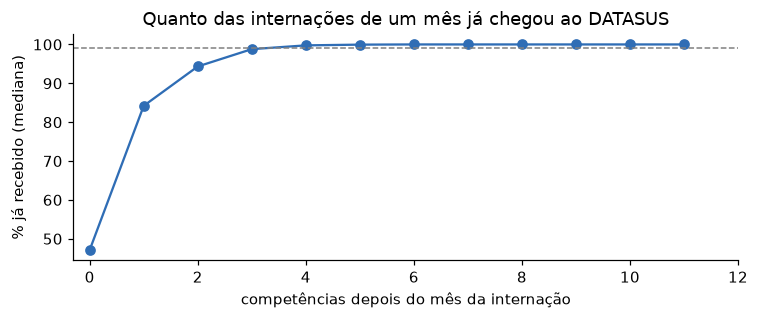

 atraso_meses  fracao_mediana
            0           0.471
            1           0.842
            2           0.943
            3           0.988
            4           0.998
            5           1.000
            6           1.000
            7           1.000


In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(completude["atraso_meses"], completude["fracao_mediana"] * 100, marker="o", color="#2f6db5")
ax.axhline(99, ls="--", color="gray", lw=1)
ax.set(xlabel="competências depois do mês da internação", ylabel="% já recebido (mediana)",
       title="Quanto das internações de um mês já chegou ao DATASUS", xlim=(-0.3, 12))
plt.tight_layout(); plt.show()
print(completude.head(8).to_string(index=False))

## 3. Olhar os dados antes de modelar

O aviso da descoberta se confirma: a internação cardiovascular de idosos em São Paulo tem pico no **inverno**, não no verão. Por isso o alvo não é "muita internação", e sim "mais internação do que nas últimas 4 semanas". A régua móvel tira a sazonalidade e deixa o pico de curto prazo.

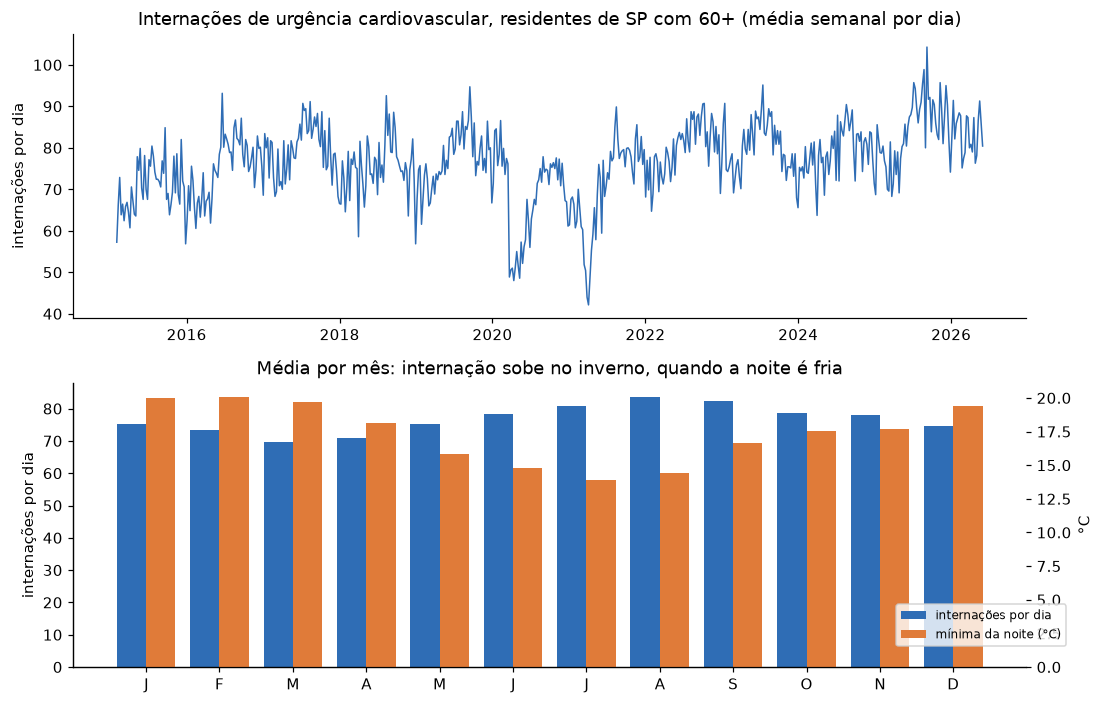

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5))
semanal = base["internacoes"].resample("W").mean()
axs[0].plot(semanal.index, semanal, color="#2f6db5", lw=1)
axs[0].set(title="Internações de urgência cardiovascular, residentes de SP com 60+ (média semanal por dia)",
           ylabel="internações por dia")
mensal = base.groupby(base.index.month)
x = np.arange(1, 13)
axs[1].bar(x - 0.2, mensal["internacoes"].mean(), 0.4, color="#2f6db5", label="internações por dia")
ax2 = axs[1].twinx()
ax2.bar(x + 0.2, mensal["tmin_noite"].mean(), 0.4, color="#e07b39", label="mínima da noite (°C)")
axs[1].set(xticks=x, xticklabels=list("JFMAMJJASOND"), ylabel="internações por dia",
           title="Média por mês: internação sobe no inverno, quando a noite é fria")
ax2.set_ylabel("°C")
fig.legend(loc="lower right", bbox_to_anchor=(0.98, 0.08), fontsize=8)
plt.tight_layout(); plt.show()

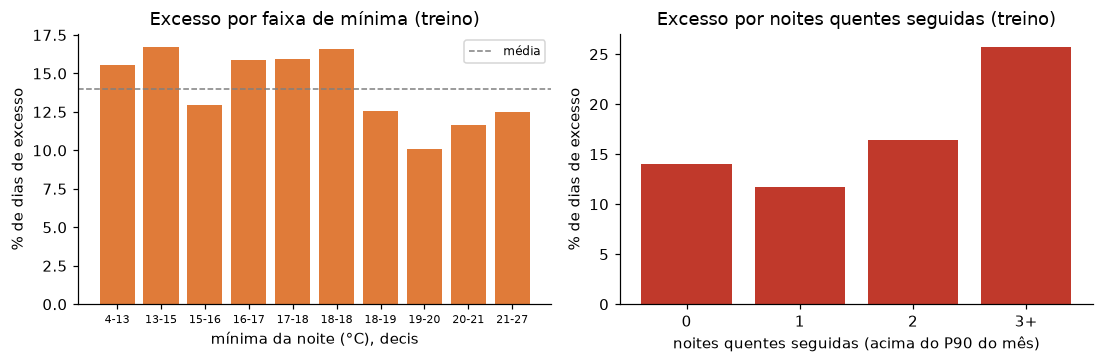

                         taxa_excesso  dias
noites_quentes_seguidas                    
0                               0.140  2949
1                               0.117   214
2                               0.164    61
3                               0.257    35


In [5]:
treino_eda = base[base.index.year <= 2023]
faixas = pd.qcut(treino_eda["tmin_noite"], 10)
por_faixa = treino_eda.groupby(faixas, observed=True)["excesso"].agg(["mean", "size"])
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].bar(range(10), por_faixa["mean"] * 100, color="#e07b39")
axs[0].axhline(treino_eda["excesso"].mean() * 100, ls="--", color="gray", lw=1, label="média")
axs[0].set(xticks=range(10), xticklabels=[f"{i.left:.0f}-{i.right:.0f}" for i in por_faixa.index],
           xlabel="mínima da noite (°C), decis", ylabel="% de dias de excesso", title="Excesso por faixa de mínima (treino)")
axs[0].tick_params(axis="x", labelsize=7); axs[0].legend(fontsize=8)
seguidas = treino_eda.groupby(treino_eda["noites_quentes_seguidas"].clip(upper=3))["excesso"].agg(["mean", "size"])
axs[1].bar(seguidas.index.astype(str), seguidas["mean"] * 100, color="#c0392b")
axs[1].set(xticks=range(4), xticklabels=["0", "1", "2", "3+"], xlabel="noites quentes seguidas (acima do P90 do mês)",
           ylabel="% de dias de excesso", title="Excesso por noites quentes seguidas (treino)")
plt.tight_layout(); plt.show()
print(seguidas.rename(columns={"mean": "taxa_excesso", "size": "dias"}).to_string())

A taxa de excesso quase não muda com a mínima absoluta da noite. A curva sobe um pouco só com 3 ou mais noites quentes seguidas, que são raras (35 dias em 9 anos). Uma pista do que acontece: como o alvo compara o dia com as 4 semanas anteriores, o que pesa é a noite estar **mais quente do que a semana anterior**, e não estar quente em si. O gráfico abaixo usa só o treino e não entra no modelo (ver seção 12).

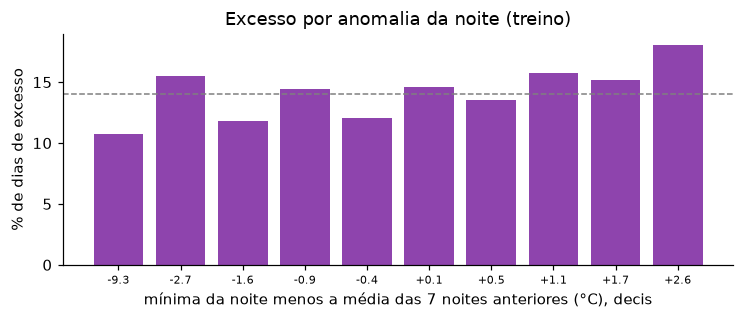

decil mais frio: 10.7% de excesso | decil mais quente: 18.0%


In [6]:
anomalia = treino_eda["tmin_noite"] - base["tmin_noite"].shift(1).rolling(7).mean().reindex(treino_eda.index)
por_anom = treino_eda.groupby(pd.qcut(anomalia, 10), observed=True)["excesso"].mean()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(10), por_anom * 100, color="#8e44ad")
ax.axhline(treino_eda["excesso"].mean() * 100, ls="--", color="gray", lw=1)
ax.set(xticks=range(10), xticklabels=[f"{i.left:+.1f}" for i in por_anom.index], ylabel="% de dias de excesso",
       xlabel="mínima da noite menos a média das 7 noites anteriores (°C), decis",
       title="Excesso por anomalia da noite (treino)")
ax.tick_params(axis="x", labelsize=7); plt.tight_layout(); plt.show()
print(f"decil mais frio: {por_anom.iloc[0]:.1%} de excesso | decil mais quente: {por_anom.iloc[-1]:.1%}")

## 4. Variáveis: só o que se sabe às 05h

| Variável | O que é | Disponível às 05h? |
|---|---|---|
| `tmin_noite` | mínima entre 18h de ontem e 05h de hoje | sim, termina às 05h |
| `tmin_noite_anterior` | a mesma mínima, uma noite antes | sim |
| `tmax_ontem` | máxima do dia de ontem | sim |
| `umidade_media` | umidade relativa média de ontem | sim |
| `noites_quentes_seguidas` | noites seguidas com mínima acima do P90 do mês (P90 medido só nos anos de treino) | sim |
| `mes`, `dia_da_semana` | calendário | sim |

**O que ficou de fora de propósito:** a internação de ontem. Ela parece a melhor variável, mas o SIH só publica a internação meses depois, então às 05h ninguém sabe quantos idosos foram internados ontem. Usá-la seria vazamento. A máxima de *hoje* também fica de fora, porque só se conhece à tarde.

In [7]:
VARIAVEIS = ["tmin_noite", "tmin_noite_anterior", "tmax_ontem", "umidade_media",
             "noites_quentes_seguidas", "mes", "dia_da_semana"]
QUENTE = [10, 11, 12, 1, 2, 3]  # estação quente: outubro a março

treino = base[base.index.year <= 2023]
teste = base[base.index >= "2024-01-01"]
Xtr, ytr = treino[VARIAVEIS], treino["excesso"]
Xte, yte = teste[VARIAVEIS], teste["excesso"]
print(f"treino: {treino.index.min():%d/%m/%Y} a {treino.index.max():%d/%m/%Y}, {len(treino)} dias, {ytr.mean():.1%} de excesso")
print(f"teste:  {teste.index.min():%d/%m/%Y} a {teste.index.max():%d/%m/%Y}, {len(teste)} dias, {yte.mean():.1%} de excesso")
print("datas sobrepostas:", len(treino.index.intersection(teste.index)))

treino: 29/01/2015 a 31/12/2023, 3259 dias, 14.0% de excesso
teste:  01/01/2024 a 31/05/2026, 882 dias, 13.0% de excesso
datas sobrepostas: 0


## 5. Divisão no tempo

A divisão é cronológica: **treino de 2015 a 2023, teste de 2024 em diante**. Embaralhar os dias deixaria o modelo ver o dia seguinte de uma onda de calor no treino e o dia anterior no teste, o que infla o resultado. O teste só é tocado no fim.

## 6. A regra simples (baseline obrigatória)

"Dia crítico quando a mínima da noite passa de X °C em 2 noites seguidas." O X é escolhido **só no treino**, pelo melhor F1, com um teto: a regra não pode abrir o radar em mais de 15% dos dias (cerca de 55 por ano). Sem esse teto, o melhor F1 vira "abrir quase todo dia", o que acaba com a ideia de um radar que só liga quando precisa. O mesmo teto vale para o modelo.

In [8]:
ORCAMENTO = 0.15  # no máximo 15% dos dias com radar aberto


def regra(df, limite):
    return ((df["tmin_noite"] > limite) & (df["tmin_noite_anterior"] > limite)).astype(int)


def escore_regra(df):
    """Versão contínua da regra: a menor das duas mínimas. Serve para a PR-AUC da baseline."""
    return df[["tmin_noite", "tmin_noite_anterior"]].min(axis=1).fillna(-99)


candidatos = np.round(np.arange(14, 25.01, 0.1), 1)
tabela_regra = pd.DataFrame({
    "limite": candidatos,
    "f1": [f1_score(ytr, regra(treino, c), zero_division=0) for c in candidatos],
    "taxa_alerta": [regra(treino, c).mean() for c in candidatos],
})
ok = tabela_regra[tabela_regra["taxa_alerta"] <= ORCAMENTO]
LIMITE = float(ok.loc[ok["f1"].idxmax(), "limite"])
dispara = regra(treino, LIMITE)
P_SE_DISPARA = float(ytr[dispara == 1].mean())
P_SE_NAO = float(ytr[dispara == 0].mean())
print(f"limite escolhido no treino: {LIMITE} °C | radar aberto em {dispara.mean():.1%} dos dias de treino")
print(f"P(excesso | regra dispara) = {P_SE_DISPARA:.3f}   P(excesso | não dispara) = {P_SE_NAO:.3f}   "
      f"razão = {P_SE_DISPARA / P_SE_NAO:.2f}")

limite escolhido no treino: 19.9 °C | radar aberto em 12.6% dos dias de treino
P(excesso | regra dispara) = 0.110   P(excesso | não dispara) = 0.145   razão = 0.76


## 7. XGBoost com busca em grade e validação cruzada no tempo

**Por que XGBoost:** a base é tabular e pequena (cerca de 3 mil dias de treino), com relações não lineares (o calor só pesa acima de um patamar) e interação entre variáveis (noite quente pesa diferente em janeiro e em julho). Árvores com boosting capturam isso sem escalar variável, aceitam dado ausente (dias sem leitura do INMET) e lidam com classe rara pelo `scale_pos_weight`. Está na lista de modelos permitidos.

**Grade:** 3 hiperparâmetros, 4 x 3 x 2 = **24 combinações**: `max_depth` {3, 4, 5, 6}, `learning_rate` {0,03; 0,1; 0,3}, `n_estimators` {100, 300}.

**Validação:** `TimeSeriesSplit(n_splits=5, gap=3)`, **só nos anos de treino**. Cada dobra treina no passado e valida nos meses seguintes, com 3 dias de folga para a onda de calor não atravessar a fronteira. A métrica de escolha é a PR-AUC (`average_precision`), que é a que importa para classe rara.

In [9]:
SPW = float((ytr == 0).sum() / ytr.sum())
GRADE = {"max_depth": [3, 4, 5, 6], "learning_rate": [0.03, 0.1, 0.3], "n_estimators": [100, 300]}
CV = TimeSeriesSplit(n_splits=5, gap=3)


def novo_xgb(**kw):
    return xgb.XGBClassifier(objective="binary:logistic", scale_pos_weight=SPW, tree_method="hist",
                             random_state=SEMENTE, n_jobs=4, **kw)


def buscar(X, y):
    g = GridSearchCV(novo_xgb(), GRADE, scoring="average_precision", cv=CV, return_train_score=True, refit=True)
    return g.fit(X, y)


busca = buscar(Xtr, ytr)
res = pd.DataFrame(busca.cv_results_)
grade = res[["param_max_depth", "param_learning_rate", "param_n_estimators",
             "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
grade.columns = ["max_depth", "learning_rate", "n_estimators", "PR-AUC treino (dobras)",
                 "PR-AUC validação (média)", "desvio validação", "posição"]
print(f"scale_pos_weight = {SPW:.2f} | combinações testadas: {len(grade)}")
print("melhor:", busca.best_params_, f"PR-AUC de validação = {busca.best_score_:.3f}")
grade.sort_values("posição")

scale_pos_weight = 6.13 | combinações testadas: 24
melhor: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100} PR-AUC de validação = 0.175


,max_depth,learning_rate,n_estimators,PR-AUC treino (dobras),PR-AUC validação (média),desvio validação,posição
0,3,0.03,100,0.438,0.175,0.018,1
2,4,0.03,100,0.568,0.174,0.015,2
1,3,0.03,300,0.630,0.167,0.009,3
8,3,0.10,100,0.667,0.167,0.006,4
3,4,0.03,300,0.798,0.165,0.009,5
10,4,0.10,100,0.828,0.165,0.011,6
6,6,0.03,100,0.831,0.163,0.021,7
4,5,0.03,100,0.699,0.163,0.008,8
18,4,0.30,100,0.973,0.162,0.021,9
7,6,0.03,300,0.970,0.161,0.019,10


### 7.1 Limiar de decisão

O XGBoost devolve uma chance. Para virar "abre ou não abre o radar", o limiar sai das previsões fora da dobra da validação cruzada (nunca do teste), com o mesmo critério da regra: melhor F1 com o radar aberto em no máximo 15% dos dias.

In [10]:
oof_p, oof_y = [], []
for i_tr, i_va in CV.split(Xtr):
    m = novo_xgb(**busca.best_params_).fit(Xtr.iloc[i_tr], ytr.iloc[i_tr])
    oof_p.append(m.predict_proba(Xtr.iloc[i_va])[:, 1]); oof_y.append(ytr.iloc[i_va].to_numpy())
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)


def escolher_limiar(p, y):
    linhas = [(t, f1_score(y, p >= t, zero_division=0), (p >= t).mean()) for t in np.unique(np.round(p, 3))]
    t = pd.DataFrame(linhas, columns=["limiar", "f1", "taxa"])
    t = t[t["taxa"] <= ORCAMENTO]
    return float(t.loc[t["f1"].idxmax(), "limiar"])


LIMIAR = escolher_limiar(oof_p, oof_y)
print(f"limiar escolhido na validação: {LIMIAR:.3f} | PR-AUC fora da dobra: {average_precision_score(oof_y, oof_p):.3f}")

limiar escolhido na validação: 0.558 | PR-AUC fora da dobra: 0.165


## 8. Resultados em treino e teste, lado a lado

In [11]:
modelo = busca.best_estimator_


def metricas(y, escore, decisao):
    return {
        "recall": recall_score(y, decisao, zero_division=0),
        "precisão": precision_score(y, decisao, zero_division=0),
        "F1": f1_score(y, decisao, zero_division=0),
        "PR-AUC": average_precision_score(y, escore),
        "ROC-AUC": roc_auc_score(y, escore),
        "% dias com radar": decisao.mean(),
        "% dias de excesso": y.mean(),
    }


def avaliar(mdl, limiar, tr, te):
    p_tr, p_te = mdl.predict_proba(tr[VARIAVEIS])[:, 1], mdl.predict_proba(te[VARIAVEIS])[:, 1]
    linhas = {
        ("XGBoost", "treino"): metricas(tr["excesso"], p_tr, (p_tr >= limiar).astype(int)),
        ("XGBoost", "teste"): metricas(te["excesso"], p_te, (p_te >= limiar).astype(int)),
        ("Regra da noite quente", "treino"): metricas(tr["excesso"], escore_regra(tr), regra(tr, LIMITE)),
        ("Regra da noite quente", "teste"): metricas(te["excesso"], escore_regra(te), regra(te, LIMITE)),
    }
    return pd.DataFrame(linhas).T, p_tr, p_te


resultado, p_tr, p_te = avaliar(modelo, LIMIAR, treino, teste)
resultado.round(3)

recall  precisão     F1  PR-AUC  ROC-AUC  \
XGBoost               treino   0.274     0.338  0.302   0.307    0.718   
                      teste    0.122     0.140  0.130   0.150    0.549   
Regra da noite quente treino   0.098     0.110  0.104   0.124    0.456   
                      teste    0.087     0.060  0.071   0.116    0.441   

                              % dias com radar  % dias de excesso  
XGBoost               treino             0.114               0.14  
                      teste              0.113               0.13  
Regra da noite quente treino             0.126               0.14  
                      teste              0.190               0.13

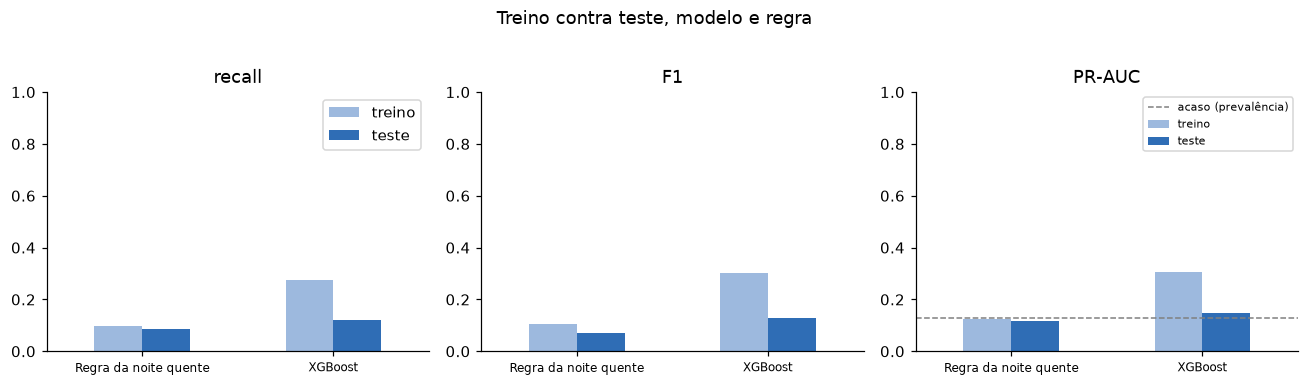

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, nome in zip(axs, ["recall", "F1", "PR-AUC"]):
    v = resultado[nome].unstack()
    v[["treino", "teste"]].plot.bar(ax=ax, color=["#9db9de", "#2f6db5"], rot=0, legend=ax is axs[0])
    if nome == "PR-AUC":
        ax.axhline(yte.mean(), ls="--", color="gray", lw=1, label="acaso (prevalência)")
        ax.legend(fontsize=7)
    ax.set(title=nome, xlabel="", ylim=(0, 1))
    ax.tick_params(axis="x", labelsize=8)
plt.suptitle("Treino contra teste, modelo e regra", y=1.02); plt.tight_layout(); plt.show()

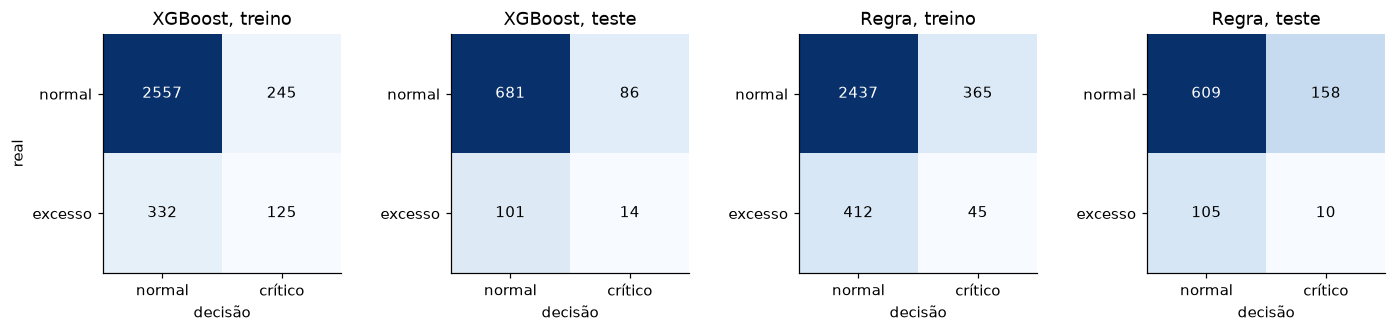

In [13]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
casos = [("XGBoost, treino", ytr, p_tr >= LIMIAR), ("XGBoost, teste", yte, p_te >= LIMIAR),
         ("Regra, treino", ytr, regra(treino, LIMITE)), ("Regra, teste", yte, regra(teste, LIMITE))]
for ax, (titulo, y, d) in zip(axs, casos):
    cm = confusion_matrix(y, d)
    ax.imshow(cm, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        ax.text(j, i, n, ha="center", va="center", color="white" if n > cm.max() / 2 else "black")
    ax.set(title=titulo, xticks=[0, 1], yticks=[0, 1], xticklabels=["normal", "crítico"],
           yticklabels=["normal", "excesso"], xlabel="decisão", ylabel="real" if ax is axs[0] else "")
plt.tight_layout(); plt.show()

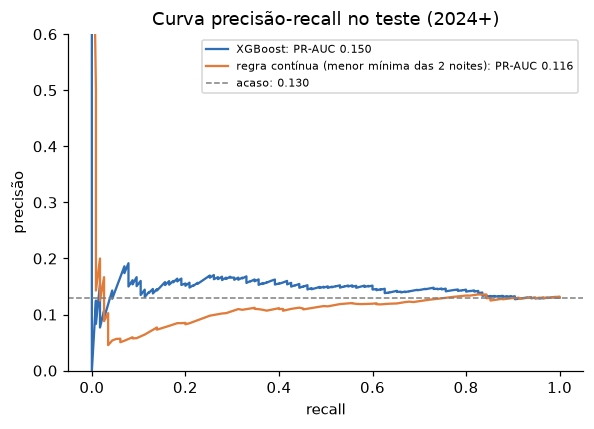

In [14]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for nome, escore, cor in [("XGBoost", p_te, "#2f6db5"), ("regra contínua (menor mínima das 2 noites)", escore_regra(teste), "#e07b39")]:
    pr, rc, _ = precision_recall_curve(yte, escore)
    ax.plot(rc, pr, color=cor, label=f"{nome}: PR-AUC {average_precision_score(yte, escore):.3f}")
ax.axhline(yte.mean(), ls="--", color="gray", lw=1, label=f"acaso: {yte.mean():.3f}")
ax.set(xlabel="recall", ylabel="precisão", title="Curva precisão-recall no teste (2024+)", ylim=(0, 0.6))
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

## 9. Overfitting

O gráfico mostra, para as 24 combinações, a PR-AUC nas dobras de treino e na validação. A distância entre as duas linhas é o quanto o modelo decorou o treino.

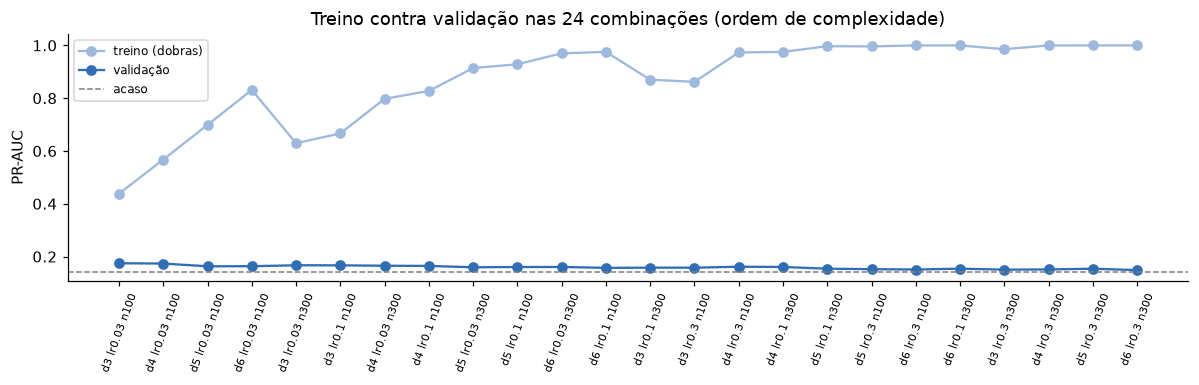

In [15]:
g = grade.copy()
g["rótulo"] = [f"d{d} lr{lr} n{n}" for d, lr, n in zip(g["max_depth"], g["learning_rate"], g["n_estimators"])]
g["complexidade"] = g["max_depth"] * g["n_estimators"] * g["learning_rate"]
g = g.sort_values("complexidade")
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(g["rótulo"], g["PR-AUC treino (dobras)"], marker="o", color="#9db9de", label="treino (dobras)")
ax.plot(g["rótulo"], g["PR-AUC validação (média)"], marker="o", color="#2f6db5", label="validação")
ax.axhline(ytr.mean(), ls="--", color="gray", lw=1, label="acaso")
ax.set(ylabel="PR-AUC", title="Treino contra validação nas 24 combinações (ordem de complexidade)")
ax.tick_params(axis="x", rotation=70, labelsize=7); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Leitura do overfitting:**

- **A grade inteira empata na validação.** As 24 combinações ficam entre 0,149 e 0,175 de PR-AUC, e o desvio entre dobras é de 0,01 a 0,02. A ordem do ranking é quase ruído. A busca escolheu a combinação mais simples (`max_depth=3`, `learning_rate=0,03`, `n_estimators=100`), e as mais complexas ficaram no fim.
- **Quanto mais complexa, mais decora.** Nas dobras de treino, a PR-AUC sobe de 0,438 para 1,000 nas combinações complexas, enquanto a validação cai de 0,175 para cerca de 0,15. Uma PR-AUC de 1,000 no treino com 0,15 fora dele é o retrato do overfitting: o modelo lembra cada dia do treino e não acha regra que se repita.
- **O modelo escolhido também perde no teste.** PR-AUC 0,307 no treino completo contra 0,150 no teste; recall 0,274 contra 0,122. A queda é grande porque não existe sinal forte a aprender: o que o modelo pega no treino é, em boa parte, coincidência daqueles anos.
- **O teste do alvo embaralhado confirma que não há vazamento.** Com o alvo sorteado, a validação dá 0,154, quase o acaso (0,140). Com o alvo real, 0,175. A diferença é pequena, o que bate com um sinal fraco, e não com um vazamento (que daria um resultado bom demais).

### 9.1 Checagem de vazamento

Um resultado bom demais costuma ser vazamento. Duas checagens: (a) o mesmo modelo treinado com o alvo **embaralhado** tem de cair no acaso; (b) a variável mais importante tem de fazer sentido físico.

PR-AUC de validação com alvo embaralhado: 0.154 (acaso = 0.140); com o alvo real: 0.175


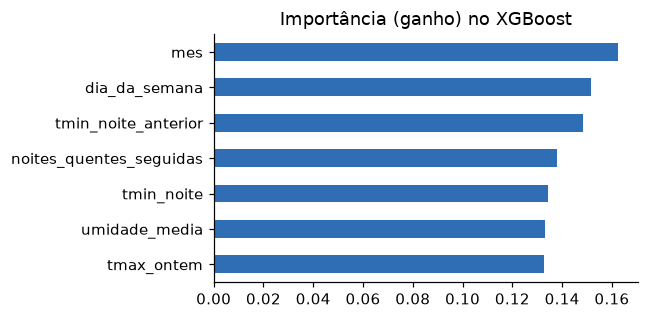

In [16]:
rng = np.random.default_rng(SEMENTE)
y_embaralhado = pd.Series(rng.permutation(ytr.to_numpy()), index=ytr.index)
aps = []
for i_tr, i_va in CV.split(Xtr):
    m = novo_xgb(**busca.best_params_).fit(Xtr.iloc[i_tr], y_embaralhado.iloc[i_tr])
    aps.append(average_precision_score(y_embaralhado.iloc[i_va], m.predict_proba(Xtr.iloc[i_va])[:, 1]))
print(f"PR-AUC de validação com alvo embaralhado: {np.mean(aps):.3f} (acaso = {ytr.mean():.3f}); "
      f"com o alvo real: {busca.best_score_:.3f}")
imp = pd.Series(modelo.get_booster().get_score(importance_type="gain")).reindex(VARIAVEIS).fillna(0)
(imp / imp.sum()).sort_values().plot.barh(figsize=(6, 3), color="#2f6db5", title="Importância (ganho) no XGBoost")
plt.tight_layout(); plt.show()

## 10. Só a estação quente (outubro a março)

A pergunta do produto é sobre calor. Duas leituras: (a) o modelo do ano todo avaliado só nos dias quentes do teste; (b) um modelo treinado **só** com dias de outubro a março, com a mesma grade e a mesma validação no tempo.

In [17]:
tr_q = treino[treino.index.month.isin(QUENTE)]
te_q = teste[teste.index.month.isin(QUENTE)]
res_q_ano, _, _ = avaliar(modelo, LIMIAR, tr_q, te_q)
busca_q = buscar(tr_q[VARIAVEIS], tr_q["excesso"])
oq_p, oq_y = [], []
for i_tr, i_va in CV.split(tr_q):
    m = novo_xgb(**busca_q.best_params_).fit(tr_q[VARIAVEIS].iloc[i_tr], tr_q["excesso"].iloc[i_tr])
    oq_p.append(m.predict_proba(tr_q[VARIAVEIS].iloc[i_va])[:, 1]); oq_y.append(tr_q["excesso"].iloc[i_va].to_numpy())
LIMIAR_Q = escolher_limiar(np.concatenate(oq_p), np.concatenate(oq_y))
res_q, _, _ = avaliar(busca_q.best_estimator_, LIMIAR_Q, tr_q, te_q)
quente = pd.concat({"(a) modelo do ano todo": res_q_ano, "(b) modelo só da estação quente": res_q})
print(f"estação quente: treino {len(tr_q)} dias, teste {len(te_q)} dias | melhor grade (b): {busca_q.best_params_}")
quente.round(3)

estação quente: treino 1612 dias, teste 455 dias | melhor grade (b): {'learning_rate': 0.3, 'max_depth': 5, 'n_estimators': 300}


recall  \
(a) modelo do ano todo          XGBoost               treino   0.100   
                                                      teste    0.037   
                                Regra da noite quente treino   0.206   
                                                      teste    0.185   
(b) modelo só da estação quente XGBoost               treino   1.000   
                                                      teste    0.148   
                                Regra da noite quente treino   0.206   
                                                      teste    0.185   

                                                              precisão     F1  \
(a) modelo do ano todo          XGBoost               treino     0.391  0.159   
                                                      teste      0.182  0.062   
                                Regra da noite quente treino     0.102  0.136   
                                                      teste      0.070  0.102   
(b) modelo só da estação quente XGBoost               treino     0.994  0.997   
                                                      teste      0.094  0.115   
                                Regra da noite quente treino     0.102  0.136   
                                                      teste      0.070  0.102   

                                                              PR-AUC  ROC-AUC  \
(a) modelo do ano todo          XGBoost               treino   0.248    0.729   
                                                      teste    0.146    0.551   
                                Regra da noite quente treino   0.102    0.462   
                                                      teste    0.110    0.421   
(b) modelo só da estação quente XGBoost               treino   1.000    1.000   
                                                      teste    0.105    0.451   
                                Regra da noite quente treino   0.102    0.462   
                                                      teste    0.110    0.421   

                                                              % dias com radar  \
(a) modelo do ano todo          XGBoost               treino             0.029   
                                                      teste              0.024   
                                Regra da noite quente treino             0.225   
                                                      teste              0.312   
(b) modelo só da estação quente XGBoost               treino             0.112   
                                                      teste              0.187   
                                Regra da noite quente treino             0.225   
                                                      teste              0.312   

                                                              % dias de excesso  
(a) modelo do ano todo          XGBoost               treino              0.112  
                                                      teste               0.119  
                                Regra da noite quente treino              0.112  
                                                      teste               0.119  
(b) modelo só da estação quente XGBoost               treino              0.112  
                                                      teste               0.119  
                                Regra da noite quente treino              0.112  
                                                      teste               0.119

Na estação quente, só 11,9% dos dias do teste são de excesso. A regra abre o radar em 31% desses dias e acerta menos que o acaso (PR-AUC 0,110). O modelo do ano todo quase não abre o radar no verão (2,4% dos dias), porque aprendeu que o excesso aparece mais no inverno. O modelo treinado só com o verão é o caso mais claro de overfitting do notebook: a validação no tempo escolheu a combinação mais complexa da grade, que acerta 100% no treino (PR-AUC 1,000) e cai para 0,105 no teste, abaixo do acaso. **Também no recorte de calor, não há sinal que o modelo consiga levar para anos novos.**

## 11. Decisão: o modelo vai para produção?

Critério combinado na descoberta, antes de qualquer resultado: o XGBoost precisa ter, **no teste**, recall maior ou igual ao da regra **e** PR-AUC maior que a da regra contínua.

In [18]:
mt, rt = resultado.loc[("XGBoost", "teste")], resultado.loc[("Regra da noite quente", "teste")]
PASSA_PONTUAL = bool(mt["recall"] >= rt["recall"] and mt["PR-AUC"] > rt["PR-AUC"])
print(f"teste | XGBoost: recall {mt['recall']:.3f}, PR-AUC {mt['PR-AUC']:.3f} | "
      f"regra: recall {rt['recall']:.3f}, PR-AUC {rt['PR-AUC']:.3f}")
print("passa no critério pelas médias?", PASSA_PONTUAL)

disp_te = regra(teste, LIMITE)
p1, p0 = yte[disp_te == 1].mean(), yte[disp_te == 0].mean()
print(f"no teste: P(excesso | regra dispara) = {p1:.3f} em {disp_te.sum()} dias; "
      f"P(excesso | não dispara) = {p0:.3f}; razão = {p1 / p0:.2f}")

teste | XGBoost: recall 0.122, PR-AUC 0.150 | regra: recall 0.087, PR-AUC 0.116
passa no critério pelas médias? True
no teste: P(excesso | regra dispara) = 0.060 em 168 dias; P(excesso | não dispara) = 0.147; razão = 0.40


Pelas médias, o modelo passa. Antes de confiar, duas perguntas: a vantagem é maior que o ruído do teste? E o modelo acerta pelo motivo certo?

### 11.1 A vantagem é maior que o ruído?

O teste tem 882 dias e 115 de excesso. O teste é reamostrado em blocos de 28 dias seguidos (para respeitar a dependência entre dias vizinhos), 2.000 vezes.

In [19]:
rng = np.random.default_rng(SEMENTE)
blocos = [np.arange(i, min(i + 28, len(teste))) for i in range(0, len(teste), 28)]
y_arr, er_arr = yte.to_numpy(), escore_regra(teste).to_numpy()
dif_regra, dif_acaso = [], []
for _ in range(2000):
    idx = np.concatenate([blocos[i] for i in rng.integers(0, len(blocos), len(blocos))])
    ap_m = average_precision_score(y_arr[idx], p_te[idx])
    dif_regra.append(ap_m - average_precision_score(y_arr[idx], er_arr[idx]))
    dif_acaso.append(ap_m - y_arr[idx].mean())
IC_REGRA, IC_ACASO = np.percentile(dif_regra, [2.5, 97.5]), np.percentile(dif_acaso, [2.5, 97.5])
print(f"PR-AUC modelo - regra: {mt['PR-AUC'] - rt['PR-AUC']:+.3f}, IC 95% [{IC_REGRA[0]:+.3f}, {IC_REGRA[1]:+.3f}]")
print(f"PR-AUC modelo - acaso: {mt['PR-AUC'] - yte.mean():+.3f}, IC 95% [{IC_ACASO[0]:+.3f}, {IC_ACASO[1]:+.3f}]")

PR-AUC modelo - regra: +0.034, IC 95% [-0.017, +0.080]
PR-AUC modelo - acaso: +0.019, IC 95% [-0.001, +0.055]


### 11.2 Em que época cada um abre o radar?

Percentual de dias do teste, por mês, com radar aberto e com excesso real.

In [20]:
alertas = pd.DataFrame({"radar do modelo": p_te >= LIMIAR, "radar da regra": disp_te.astype(bool),
                        "excesso": yte.astype(bool)}, index=teste.index)
alertas.groupby(alertas.index.month).mean().mul(100).round(0).T.rename(columns=dict(enumerate("JFMAMJJASOND", 1)))

data,J,F,M,A,M,J,J,A,S,O,N,D
radar do modelo,5.0,0.0,1.0,3.0,30.0,28.0,37.0,26.0,3.0,5.0,3.0,0.0
radar da regra,34.0,60.0,32.0,13.0,11.0,0.0,0.0,0.0,7.0,0.0,8.0,39.0
excesso,12.0,9.0,15.0,11.0,14.0,20.0,18.0,10.0,15.0,6.0,22.0,6.0


### 11.3 Veredito

- **A vantagem não passa do ruído.** O intervalo de 95% da diferença de PR-AUC contra a regra inclui zero, e o intervalo contra o acaso também encosta no zero.
- **O modelo não acerta pelo motivo do produto.** Quase todos os alertas do XGBoost caem de maio a agosto, no frio. O que ele aprendeu foi um efeito da própria régua: no outono a internação sobe mês a mês, e a média das 4 semanas anteriores fica para trás, então sobra mais "excesso" no inverno. O `mes` carrega isso. Não é sinal de calor.

Por isso o resultado é tratado como **empate**, e o job usa a regra (`origem = REGRA_BASE`). Este segundo filtro (o intervalo de confiança) foi escrito **depois** de ver o primeiro resultado do teste, e fica registrado assim. Ele só pode deixar a decisão mais conservadora: nunca promove o modelo.

In [21]:
VENCE = PASSA_PONTUAL and bool(IC_REGRA[0] > 0)
ORIGEM = "MODELO" if VENCE else "REGRA_BASE"
print("o modelo vence a regra fora do ruído?", VENCE, "-> origem enviada pelo job:", ORIGEM)

o modelo vence a regra fora do ruído? False -> origem enviada pelo job: REGRA_BASE


In [22]:
MODELO.mkdir(exist_ok=True)
modelo.get_booster().save_model(MODELO / "dia_critico_xgb.json")
r = lambda d: {k: round(float(v), 4) for k, v in d.items()}  # noqa: E731
metadados = {
    "origem": ORIGEM,
    "variaveis": VARIAVEIS,
    "limiar_decisao": round(LIMIAR, 4),
    "orcamento_alertas": ORCAMENTO,
    "hiperparametros": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in busca.best_params_.items()},
    "scale_pos_weight": round(SPW, 4),
    "periodo_treino": [f"{treino.index.min():%Y-%m-%d}", f"{treino.index.max():%Y-%m-%d}"],
    "periodo_teste": [f"{teste.index.min():%Y-%m-%d}", f"{teste.index.max():%Y-%m-%d}"],
    "metricas_teste": {"modelo": r(mt), "regra_base": r(rt)},
    "regra_base": {"limite_tmin": LIMITE, "noites": 2, "prob_excesso_se_dispara": round(P_SE_DISPARA, 4),
                   "prob_excesso_se_nao_dispara": round(P_SE_NAO, 4)},
    "sha256_base_modelo": sha_base,
    "versoes": {"python": platform.python_version(), "xgboost": xgb.__version__,
                "scikit-learn": sklearn.__version__, "pandas": pd.__version__},
}
(MODELO / "metadados.json").write_text(json.dumps(metadados, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(json.dumps(metadados, ensure_ascii=False, indent=2))

{
  "origem": "REGRA_BASE",
  "variaveis": [
    "tmin_noite",
    "tmin_noite_anterior",
    "tmax_ontem",
    "umidade_media",
    "noites_quentes_seguidas",
    "mes",
    "dia_da_semana"
  ],
  "limiar_decisao": 0.558,
  "orcamento_alertas": 0.15,
  "hiperparametros": {
    "learning_rate": 0.03,
    "max_depth": 3,
    "n_estimators": 100
  },
  "scale_pos_weight": 6.1313,
  "periodo_treino": [
    "2015-01-29",
    "2023-12-31"
  ],
  "periodo_teste": [
    "2024-01-01",
    "2026-05-31"
  ],
  "metricas_teste": {
    "modelo": {
      "recall": 0.1217,
      "precisão": 0.14,
      "F1": 0.1302,
      "PR-AUC": 0.1496,
      "ROC-AUC": 0.5489,
      "% dias com radar": 0.1134,
      "% dias de excesso": 0.1304
    },
    "regra_base": {
      "recall": 0.087,
      "precisão": 0.0595,
      "F1": 0.0707,
      "PR-AUC": 0.1156,
      "ROC-AUC": 0.4405,
      "% dias com radar": 0.1905,
      "% dias de excesso": 0.1304
    }
  },
  "regra_base": {
    "limite_tmin": 19.9,
    "n

In [23]:
# O job de produção, rodado em modo seco com o clima de um dia histórico do teste.
r = subprocess.run([sys.executable, "prever_hoje.py", "--dia-das-variaveis", "2025-12-29", "--seco"],
                   capture_output=True, text=True)
print(r.stdout, r.stderr)

{"dia_das_variaveis": "2025-12-29", "critico": true, "probabilidade": 0.1098, "motivo": "demo com o clima de 29/12/2025; regra da noite quente: mínimas de 22,6 e 24,3 °C nas 2 últimas noites, acima de 19,9 °C", "origem": "REGRA_BASE"}
 


## 12. Limites deste resultado

- **O alvo mede internação, não sofrimento.** Calor mata e adoece também por desidratação, queda e piora de doença que não vira internação de urgência cardiovascular pelo SUS. E86 e T67 (desidratação e efeito do calor) quase não aparecem como diagnóstico principal. Um dia quente pode ser perigoso para quem mora sozinho sem que este alvo perceba.
- **Só SUS e só uma estação.** Internação particular fica de fora, e a A701 representa a cidade inteira com um ponto só.
- **A régua de 28 dias anteriores fica para trás quando a série sobe.** No outono, quando a internação cresce mês a mês, ela marca mais excesso. Uma régua centrada no dia, ou um modelo de contagem com sazonalidade explícita, separaria melhor pico de tendência.
- **Feriados e o efeito da pandemia** (2020 e 2021) não foram tratados à parte.
- **Próximo passo honesto:** a anomalia da noite (mínima contra a média da semana anterior) foi a única variável com gradiente visível no treino (10,7% de excesso no decil mais frio e 18,0% no mais quente). Ela foi vista depois do primeiro resultado do teste, por isso **não** entrou no modelo: testá-la agora no mesmo teste seria escolher a variável olhando a prova. O teste justo é com os meses de 2026 que o SIH ainda vai publicar.

## 13. Conclusão para o cidadão

**Em São Paulo, a noite quente não avisa, sozinha, que mais idosos vão ser internados por problema do coração.** Com 11 anos de dados reais (317 mil internações de urgência de pessoas com 60 anos ou mais e o termômetro do Mirante de Santana), nem a regra simples nem o XGBoost previram bem os dias de excesso. Nos dias em que a regra da noite quente disparou em 2024-2026, a chance de excesso foi de 6%, contra 15% nos outros dias. O XGBoost ficou um pouco acima do acaso (PR-AUC 0,150 contra 0,130), mas a vantagem cabe no ruído, e ele acertou pelo motivo errado: aprendeu o inverno, quando a internação do coração sobe.

**O que isso muda no Corredor Aceso:** o job das 05h usa a regra da noite quente (`origem = REGRA_BASE`), e manda a probabilidade honesta que a regra tem (11% de excesso no treino). O radar de calor continua fazendo sentido pelo risco direto do calor para quem mora só, pelo apagão e pelo aparelho que fica em silêncio, mas o produto **não pode prometer** que reduz internação cardiovascular. Para a ACS, a frase certa é: "hoje a noite não esfriou; passe nas casas que ficaram em silêncio", e não "hoje vai ter mais internação".

Um resultado negativo medido com cuidado também protege o cidadão: evita que a prefeitura confie num alerta que, nos dados, não se sustenta.